In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

In [2]:
PI = np.pi
gen = np.random.default_rng(seed = 26)

In [3]:
def discrete_gradient(X, h):

    grad_x = (np.roll(X, 2, axis = 1) - 8 * np.roll(X, 1, axis = 1) + \
                    8 * np.roll(X, -1 ,axis = 1) - np.roll(X, -2 ,axis = 1)) / \
                    (12 * h)

    grad_y = (np.roll(X, 2, axis = 0) - 8 * np.roll(X, 1, axis = 0) + \
                    8 * np.roll(X, -1 ,axis = 0) - np.roll(X, -2 ,axis = 0)) / \
                    (12 * h)

    return grad_x, grad_y

In [4]:
def discrete_laplacian(X, h):

    x = X.copy()
    
    x = (-np.roll(X,-2,axis = 0) + 16 * np.roll(X,-1,axis = 0) - 30 * X + 16 * np.roll(X,1,axis = 0) - np.roll(X,2,axis = 0) - 
            np.roll(X,-2,axis = 1) + 16 * np.roll(X,-1,axis = 1) - 30 * X + 16 * np.roll(X,1,axis = 1) - np.roll(X,2,axis = 1)) / (12*h**2)

    return x

In [5]:
def semi_lagrangian_tendency(X, h, dt, u, v, order=3):
    
    tend = np.zeros_like(X)

    phi = X
    Ny, Nx = phi.shape

    # index coords for the interior subarray (0..N-1)
    rows, cols = np.indices((Ny, Nx), dtype=np.float64)

    # backtrace in *index* units: shift = velocity * dt / h
    cols_b = cols - (u * dt / h)
    rows_b = rows - (v * dt / h)

    phi_back = map_coordinates(phi, [rows_b, cols_b],
                               order=order, mode='grid-wrap', prefilter=(order > 1))

    tend[1:-1,1:-1] = (phi_back[1:-1,1:-1] - phi[1:-1,1:-1]) / dt
    return tend

In [6]:
def initial_conditions(nrows, ncols, n1, p1, A, L):

    n, p = np.zeros((nrows, ncols)), np.zeros((nrows, ncols))

    for i in range(nrows):

        n[i, :] += n1 * (1 + A * np.sin((np.pi / L) * np.arange(ncols)))

    for j in range(ncols):
    
        p[:, j] += p1 * (1 + A * np.sin((np.pi / L) * np.arange(nrows)))

    return n, p

In [7]:
def dn(n, p, u, v, d, i_n, a, m_n, dx):

    reaction = i_n - a*p*n/(1 + n) - m_n*n
    advection = semi_lagrangian_tendency(n, dx, dt, u, v, order=3)
    diffussion = d * discrete_laplacian(n, dx)

    return reaction - advection + diffussion

In [8]:
def dp(n, p, u, v, d, f_p, dx):

    reaction = n*p/(1 + n) - f_p*p/(1 + p)
    advection = semi_lagrangian_tendency(p, dx, dt, u, v, order=3)
    diffussion = d * discrete_laplacian(p, dx)
    
    return reaction - advection + diffussion

In [9]:
'''Function to solve the system of equations using RK4'''
def solve_system_rk4(n_0, p_0, dt, T, u, v, d, i_n, a, m_n, f_p, dx):

    n_iter = int(T//dt)
    t_interval = np.linspace(0,T,n_iter+1)
    
    n_list = [n_0]
    p_list = [p_0]

    for _ in range(n_iter):

        prev_n = n_list[-1]
        prev_p = p_list[-1]

        k1_n = dn(prev_n, prev_p, u, v, d, i_n, a, m_n, dx)
        k1_p = dp(prev_n, prev_p, u, v, d, f_p, dx)

        k2_n = dn(prev_n + k1_n*dt/2, prev_p + k1_p*dt/2,u, v, d, i_n, a, m_n, dx)
        k2_p = dp(prev_n + k1_n*dt/2, prev_p + k1_p*dt/2, u, v, d, f_p, dx)

        k3_n = dn(prev_n + k2_n*dt/2, prev_p + k2_p*dt/2,u, v, d, i_n, a, m_n, dx)
        k3_p = dp(prev_n + k2_n*dt/2, prev_p + k2_p*dt/2, u, v, d, f_p, dx)

        k4_n = dn(prev_n + k3_n*dt/2, prev_p + k3_p*dt/2,u, v, d, i_n, a, m_n, dx)
        k4_p = dp(prev_n + k3_n*dt/2, prev_p + k3_p*dt/2, u, v, d, f_p, dx)

        new_n = prev_n + (k1_n + 2*k2_n + 2*k3_n + k4_n)*dt/6
        new_p = prev_p + (k1_p + 2*k2_p + 2*k3_p + k4_p)*dt/6

        n_list.append(new_n)
        p_list.append(new_p)

    return t_interval, n_list, p_list

In [10]:
def real_calculation_slow_phi(x, y, L_x, L_y, eta, u_0, V_d, Re_ak, Im_ak, n_max):

    n_rows, n_cols = x.shape
    flow = np.zeros([n_rows, n_cols], dtype=complex)

    d = 2
    V_d = L_x * L_y
    K = 2 * PI * np.arange(-n_max, n_max + 1) / L_x
    num = eta**(d / 2 + 1) * u_0
    den = np.sqrt(V_d * d * (d - 1)) 
    fourier_sum = np.zeros_like(flow)

    for k_1 in range(len(K)):

        for k_2 in range(n_max + 1):

            if K[k_2] == 0:

                if K[k_1] == 0:
                
                    fourier_sum += Re_ak[k_1, k_2] * np.exp(-(K[k_1]**2 + K[k_2]**2) * (eta / 2)**2)
                
                else:

                    cos_kr = np.cos(K[k_1] * x)
                    sin_kr = np.sin(K[k_1] * x)
    
                    fourier_sum += (Re_ak[k_1, k_2] * cos_kr + Im_ak[k_1, k_2] * sin_kr) * np.exp(-(K[k_1]**2) * (eta / 2)**2)
                
            else:

                cos_kr = np.cos(K[k_1] * x + K[k_2] * y)
                sin_kr = np.sin(K[k_1] * x + K[k_2] * y)

                fourier_sum += 2 *(Re_ak[k_1, k_2] * cos_kr + Im_ak[k_1, k_2] * sin_kr)  * np.exp(-(K[k_1]**2 + K[k_2]**2) * (eta / 2)**2)
           
    flow = (2 * PI)**(d/4) * num / den * fourier_sum
    flow = np.real_if_close(flow)

    return flow

In [11]:
def fourier_matrix(n_max):

    coef_real = gen.normal(0, np.sqrt(0.5), (2 * n_max + 1, 2 * n_max + 1))
    coef_im = gen.normal(0, np.sqrt(0.5), (2 * n_max + 1, 2 * n_max + 1))

    coef_real[n_max + 1:, n_max + 1:] = np.flip(coef_real[:n_max, :n_max])
    coef_im[n_max + 1:, n_max + 1:] = -np.flip(coef_im[:n_max, :n_max])

    coef_real[n_max + 1:, :n_max] = np.flip(coef_real[:n_max, n_max + 1:])
    coef_im[n_max + 1:, :n_max] = -np.flip(coef_im[:n_max, n_max + 1:])

    coef_real[n_max + 1:, n_max] = np.flip(coef_real[:n_max, n_max])
    coef_im[n_max + 1:, n_max] = -np.flip(coef_im[:n_max, n_max])
    
    coef_real[n_max, n_max + 1:] = np.flip(coef_real[n_max, :n_max])
    coef_im[n_max, n_max + 1:] = -np.flip(coef_im[n_max, :n_max])

    coef_real[n_max, n_max] = gen.normal(0, 1)
    coef_im[n_max, n_max] = 0

    coef = coef_real + 1j * coef_im

    return coef

In [12]:
def find_n_max(L, eta, tol):

    n_max = int(2 * L // eta)
    biggest_k = 2 * PI * n_max / L
    gaussian_term = np.exp(-biggest_k**2 * eta **2 / 4)

    while gaussian_term < tol:

        n_max -= 1
        biggest_k = 2 * PI * n_max / L
        gaussian_term = np.exp(-biggest_k**2 * eta **2 / 4)

    return n_max

In [13]:
n_0 = 4.07
p_0 = 0.121
i_n = 0.9
a = 8
m_n = 0.03
f_p = 0.9
d = 0.04
nu_max = 0.3
r_0 = 10
n_eddies = 100
L = 100
A = 1
T = 1000
dt = 0.12
N = 180

#dx = 2 * L / N
tol = 1e-14

eta = r_0
L_x, L_y, L_z = 2 * L, 2 * L, 0
L_tot = L_x
dx = L_tot / N
u_0 = 0.3
n_max = find_n_max(L_x, eta, tol)
V_d = L_x * L_y

In [14]:
a_k = fourier_matrix(n_max)

In [15]:
x, y = np.arange(-N//2, N//2) * dx, np.arange(-N//2, N//2) * dx
X, Y = np.meshgrid(x, y)

In [16]:
psi = real_calculation_slow_phi(X, Y, L_x, L_y, eta, u_0, V_d, np.real(a_k), np.imag(a_k), n_max)

In [17]:
psi_x, psi_y = discrete_gradient(psi, dx)

u = psi_y
v = -psi_x

In [18]:
vel_mag = np.sqrt(u**2 + v**2)
max_vel = np.max(vel_mag)
s = nu_max / max_vel

In [19]:
u *= s
v *= s

In [20]:
n, p = initial_conditions(N, N, n_0, p_0, A, L)

In [21]:
t, n_list, p_list = solve_system_rk4(n, p, dt, T, u, v, d, i_n, a, m_n, f_p, dx)

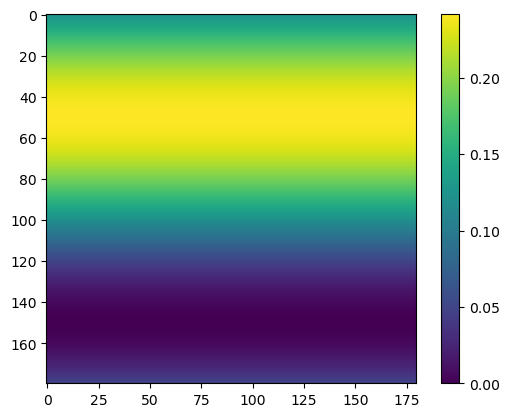

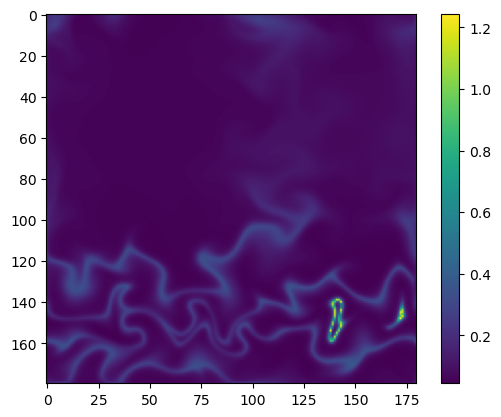

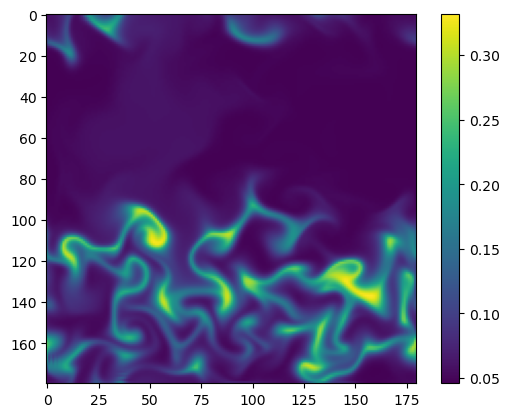

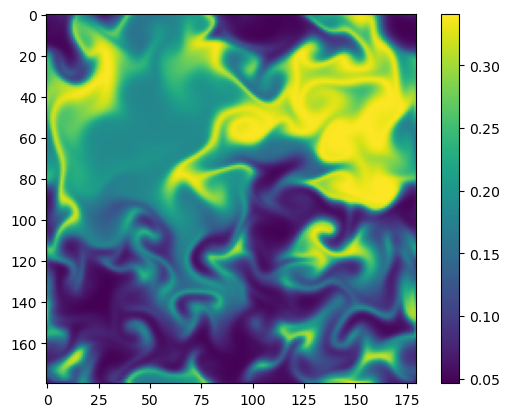

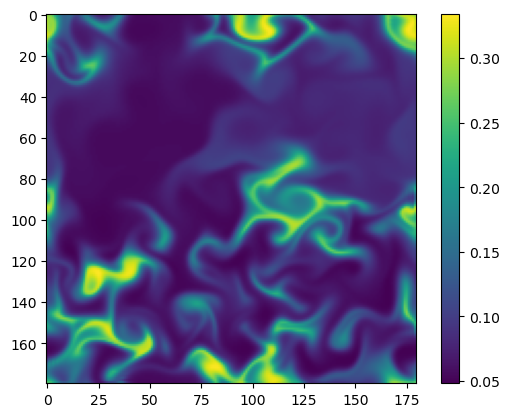

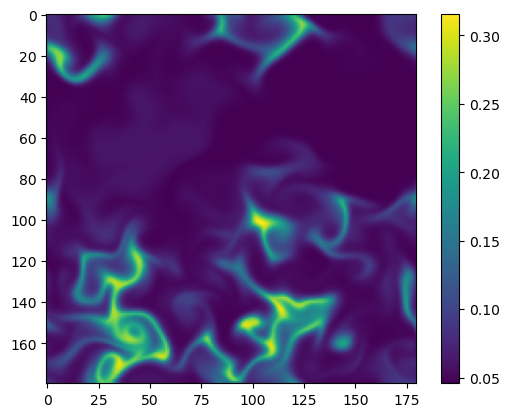

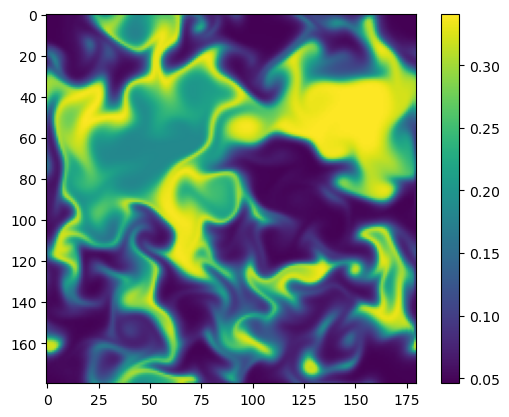

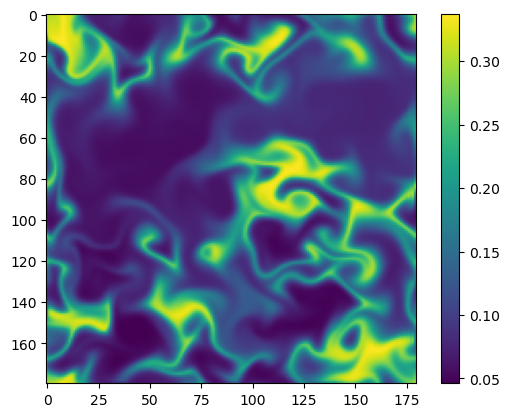

In [22]:
for i in range(8):
    plt.imshow(p_list[i*1000])
    plt.colorbar()
    plt.show()